<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [orchid](https://github.com/Gokaran-Shukla/orchid) · MIT License — any reuse must keep this copyright notice and credit the author.

# ORCHID tutorial 11: Exhaustive search, ML surrogates and Bayesian inversion

**Goals.** Extract model parameters from data by exhaustive (zooming) grid search, train Gaussian-process
surrogates of ORCHID simulations, and run Bayesian inversion with credible intervals.

### Theory
Fits minimise the log-RMSE $\sqrt{\langle(\ln y_{model}-\ln y_{data})^2\rangle}$. A GP gives a posterior mean
$\bar f_*=k_*^\top(K+\sigma_n^2I)^{-1}y$ and a variance. Bayesian inversion evaluates
$p(\theta|d)\propto e^{-\chi^2/2}p(\theta)$ on a grid and reads off marginals and 95 % intervals.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (5.4, 3.6), "axes.grid": True, "grid.alpha": 0.3})
import orchid
print("ORCHID", orchid.__version__)

ORCHID 0.4.0


In [2]:
from orchid.models import gdm_bassler
from orchid.search import zoom_search, log_rmse
TT, FF = np.meshgrid([200, 240, 280, 320.0], [1e4, 1e5, 4e5, 1e6], indexing="ij")
data = gdm_bassler(TT, FF, 0.09, 1e-2, Sigma=2.0)
best, err, _ = zoom_search(lambda p: log_rmse(gdm_bassler(TT, FF, p["sigma"], p["mu_inf"], Sigma=p["Sigma"]), data),
                           {"sigma": (0.05, 0.15), "mu_inf": (1e-5, 1.0), "Sigma": (1.5, 4)},
                           n=11, levels=4, log=("mu_inf",))
print(best, err)

{'sigma': np.float64(0.09), 'mu_inf': np.float64(0.01), 'Sigma': np.float64(2.0)} 0.0


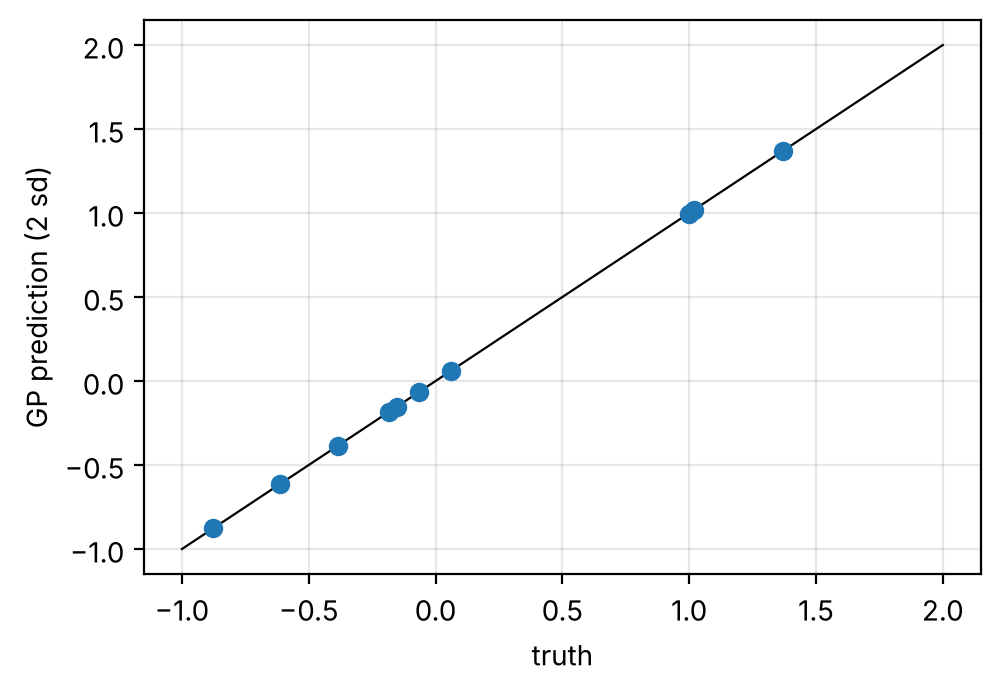

In [3]:
from orchid.ml import GPSurrogate
rng = np.random.default_rng(1)
X = rng.uniform(0, 1, (40, 2)); y = np.sin(6 * X[:, 0]) + X[:, 1] ** 2
gp = GPSurrogate().fit(X[:30], y[:30])
pr, sd = gp.predict(X[30:], return_std=True)
plt.errorbar(y[30:], pr, yerr=2 * sd, fmt="o"); plt.plot([-1, 2], [-1, 2], "k-", lw=0.8)
plt.xlabel("truth"); plt.ylabel("GP prediction (2 sd)");

In [4]:
from orchid.ml import bayes_grid
noisy = data * np.exp(rng.normal(0, 0.05, data.shape))
r = bayes_grid(lambda p: gdm_bassler(TT, FF, p["sigma"], 10 ** p["lmu"], Sigma=p["Sigma"]), noisy,
               dict(sigma=np.linspace(0.08, 0.10, 31), lmu=np.linspace(-2.5, -1.5, 31), Sigma=np.linspace(1.5, 2.5, 21)),
               0.05 / np.log(10))
print("MAP", r["map"]); print("95 % CI", r["ci95"])

MAP {'sigma': np.float64(0.09), 'lmu': np.float64(-2.0), 'Sigma': np.float64(2.0)}
95 % CI {'sigma': (0.08934640000959593, 0.09048887205243543), 'lmu': (-2.032755191704366, -1.9462961716711378), 'Sigma': (1.9218173902517584, 2.0812583382953873)}


**Exercise.** How many model evaluations would a full 31×31×21 grid need, and how many did `zoom_search` use with n=11, levels=4?

<details><summary>Solution</summary>

20 181 for the full grid. Zoom search uses $4\times11^3=5324$ and reaches finer resolution near the optimum.
</details>

## Quiz

Five questions on this section. Run the cell to see them, then grade yourself with
`quiz("11", answers="abcda")` (one letter per question). The same quiz runs in a terminal
with `orchid quiz 11`.

In [5]:
from orchid.tutorials import quiz
quiz("11")

Quiz 11: Exhaustive search, ML surrogates and Bayesian inversion

Q1. A full grid with n points per parameter in d dimensions needs
    (a) log n evaluations
    (b) d^n evaluations
    (c) n^d evaluations
    (d) n d evaluations

Q2. Why does ORCHID fit mobility data with log-RMSE?
    (a) To avoid negative mobilities only
    (b) Mobility spans many decades, so relative (log) errors weight all points fairly
    (c) Because data are linear
    (d) It is faster

Q3. A Gaussian-process surrogate provides
    (a) Only a point prediction
    (b) A predictive mean and an uncertainty; hyperparameters set by maximising the marginal likelihood
    (c) A neural network
    (d) An exact solution

Q4. V22 reports '3/3 covered'. What does that mean?
    (a) Three folds of cross-validation
    (b) Three CPUs were used
    (c) The true parameters lie inside the 95 % credible intervals for all three parameters
    (d) Three seeds agree

Q5. Latin hypercube sampling ensures that
    (a) Samples are c

In [6]:
# replace with your answers, e.g. "abcda"
# quiz("11", answers=".....")

<details><summary>Answer key</summary>

`cbbcc`. Run `quiz("11", answers="cbbcc")` to see the explanation for every question.
</details>

---
[Tutorial index](README.md) · ORCHID documentation · `orchid tutorials`